<a href="https://colab.research.google.com/github/lamaljalal/arti402/blob/main/arti402_Lab10_2240002307.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ARTI 402 — Deep Learning
## Lab 10 — Attention: Letting the Network Look Back

**Week 10 · Attention Mechanisms**
Scaled dot-product attention, self-attention, masking, and the road to transformers.

| | |
|---|---|
| **Estimated time** | 100 minutes |
| **Prerequisites** | Lab 4 (the problem) and Lab 9 (the bottleneck). Lab 2's softmax returns |
| **Reference** | Ekman, *Learning Deep Learning*, Chapter 15 |

### Read and reference

| When | Resource | Why |
|---|---|---|
| **Before class** | [3Blue1Brown — *Attention in transformers*](https://www.youtube.com/watch?v=eMlx5fFNoYc) | The best visual explanation that exists |
| **Stage 2** | [Jay Alammar — *The Illustrated Transformer*](https://jalammar.github.io/illustrated-transformer/) | Read as far as "Self-Attention in Detail" |
| **Stage 4** | [Transformer Explainer](https://poloclub.github.io/transformer-explainer/) | From the team that made CNN Explainer. Watch real attention weights move |
| **Reference** | [Vaswani et al., *Attention Is All You Need*](https://arxiv.org/abs/1706.03762) | The paper. Section 3.2 is the formula you build today |

### How to work through the notebook
* Sections are labelled **Idea** (read and run), **Exercise** (you write code) and **Checkpoint** (a short answer).
* Every exercise cell is marked `# TODO`. Do not delete the cells above it — later cells depend on them.
* Run cells **in order**, top to bottom. If something breaks, restart the kernel and run all.
* The graded **Assessment** is at the very end.

---
## Setup

In [1]:
"""
arti402_figures.py
==================
Diagram helpers for ARTI 402 — Deep Learning (Lab 3 onward).

Keep this file in the SAME FOLDER as the notebook, then import what you need:

    from arti402_figures import (draw_cnn_architecture, draw_convolution_step,
                                 draw_max_pooling, draw_lab_pipeline,
                                 draw_param_example)

Every figure is drawn from the same numbers the notebook computes, so the
pictures can never disagree with the code.

The architecture diagram will use a real photograph as its input block if one
is found next to this file (default: "Zebra_image.jpeg"). If no image is
found it falls back to a plain grey rectangle, so the notebook always runs.

You do not need to read or understand this file to complete the lab.
"""

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

__all__ = [
    "draw_cnn_architecture", "draw_convolution_step", "draw_max_pooling",
    "draw_shape_journey", "draw_lab_pipeline", "draw_param_example",
    "INPUT_IMAGE_CANDIDATES",
    # Lab 4
    "draw_unrolled_rnn", "draw_repeated_multiplication", "draw_lstm_cell",
    "draw_recurrent_params", "draw_lab4_pipeline",
    # Lab 5
    "draw_spiral_data", "draw_optimizer_family", "draw_valley_paths",
    "draw_loss_curves", "draw_decision_boundaries",
    # Lab 6
    "draw_overfitting_curves", "draw_weight_histograms", "draw_init_depth",
    "draw_batchnorm_effect",
    # Lab 9
    "draw_autoencoder_architecture", "draw_digit_grid", "draw_latent_space",
    "draw_bottleneck_sweep",
    # Lab 10
    "draw_bottleneck_vs_attention", "draw_attention_heatmap",
    "draw_qkv_mechanism", "draw_length_sweep",
]

# ----------------------------------------------------------------- palette
LEARN = "#E8A33D"     # blocks WITH learnable parameters
FIXED = "#8FB8D6"     # blocks with NO parameters
EDGE = "#333333"
GREY = "#DCDCDC"
OUTC = "#F3D9B1"

# Filenames tried, in order, for the architecture diagram's input block.
INPUT_IMAGE_CANDIDATES = [
    "Zebra_image.jpeg", "Zebra_image.jpg", "Zebra_image.png", "Zebra_image",
]


# ----------------------------------------------------------------- helpers
def _find_input_image(path=None):
    """Return a path to the input photo, or None if there isn't one."""
    here = os.path.dirname(os.path.abspath(__file__))
    candidates = [path] if path else []
    candidates += INPUT_IMAGE_CANDIDATES
    for name in candidates:
        if not name:
            continue
        for full in (name, os.path.join(here, name)):
            if os.path.isfile(full):
                return full
    return None


def _center_crop(img, target_aspect):
    """Centre-crop an (H, W, C) array to the given width/height aspect ratio."""
    h, w = img.shape[:2]
    if w / h > target_aspect:                 # too wide -> trim the sides
        new_w = int(round(h * target_aspect))
        x0 = (w - new_w) // 2
        return img[:, x0:x0 + new_w]
    new_h = int(round(w / target_aspect))     # too tall -> trim top/bottom
    y0 = (h - new_h) // 2
    return img[y0:y0 + new_h, :]


def _stack(ax, x, y, w, h, n, color, dx=.055, dy=.045):
    """n offset rectangles, to suggest a stack of feature maps."""
    for i in range(n - 1, -1, -1):
        ax.add_patch(Rectangle((x + i * dx, y + i * dy), w, h, facecolor=color,
                               edgecolor=EDGE, lw=1.1, zorder=10 - i))


def _arrow(ax, x0, x1, y):
    ax.annotate("", xy=(x1, y), xytext=(x0, y),
                arrowprops=dict(arrowstyle="-|>", lw=1.4, color="#555"))


# ------------------------------------------------------------------ FIG 1
def draw_cnn_architecture(image_path=None, verbose=True):
    """The four building blocks, end to end.

    image_path : optional path to a photo for the input block.
    """
    fig, ax = plt.subplots(figsize=(13.5, 4.9))
    ax.set_xlim(0, 15.2)
    ax.set_ylim(-1.5, 3.9)
    ax.axis("off")
    mid, BLK_Y = 1.5, 2.92

    # ---- input block: a real photo if we can find one -------------------
    ix, iw, ih = .15, 1.35, 1.55
    iy0, iy1 = mid - ih / 2, mid + ih / 2
    found = _find_input_image(image_path)
    if found is not None:
        photo = plt.imread(found)
        if photo.ndim == 2:
            photo = np.stack([photo] * 3, axis=-1)
        photo = _center_crop(photo[:, :, :3], iw / ih)
        ax.imshow(photo, extent=(ix, ix + iw, iy0, iy1),
                  aspect="auto", origin="upper", zorder=2)
    else:
        ax.add_patch(Rectangle((ix, iy0), iw, ih, facecolor=GREY,
                               edgecolor=EDGE, lw=1.1, zorder=2))
        ax.text(ix + iw / 2, mid, "image", ha="center", va="center",
                fontsize=9, color="#666", zorder=3)
        if verbose:
            print("note: no input photo found, using a grey placeholder.\n"
                  "      put Zebra_image.jpeg next to the notebook to show a real image.")

    ax.add_patch(Rectangle((ix, iy0), iw, ih, facecolor="none",
                           edgecolor=EDGE, lw=1.3, zorder=4))
    ax.text(ix + iw / 2, iy1 + .16, "Input", ha="center", fontsize=11,
            weight="bold")

    # the little kernel window, placed over the stripes
    ks = .26
    kx, ky = ix + .42, mid + .16
    ax.add_patch(Rectangle((kx, ky), ks, ks, facecolor="none",
                           edgecolor="#FFD24A", lw=2.4, zorder=6))
    ax.text(kx + ks / 2, ky + ks + .10, "kernel", ha="center", va="center",
            fontsize=7.4, color="#FFFFFF", zorder=7,
            bbox=dict(boxstyle="round,pad=0.16", fc="#000000AA", ec="none"))

    _arrow(ax, ix + iw + .10, 1.85, mid)

    # ---- convolution / pooling stacks -----------------------------------
    blocks = [(1.95, .95, 1.75, 5, LEARN, "Convolution\n+ ReLU", "BLOCK 1"),
              (3.75, 1.08, 1.50, 5, FIXED, "Pooling", "BLOCK 2"),
              (5.45, .80, 1.20, 8, LEARN, "Convolution\n+ ReLU", "BLOCK 1"),
              (7.05, .92, .95, 8, FIXED, "Pooling", "BLOCK 2")]
    for i, (x, w, h, n, col, lbl, blk) in enumerate(blocks):
        _stack(ax, x, mid - h / 2, w, h, n, col)
        ax.text(x + w / 2 + .12, mid - h / 2 - .42, lbl, ha="center",
                fontsize=8.6, linespacing=1.25)
        ax.text(x + w / 2 + .12, BLK_Y, blk, ha="center", fontsize=7.2,
                color="#777", style="italic")
        if i < 3:
            _arrow(ax, x + w + .42, blocks[i + 1][0] - .08, mid)
    _arrow(ax, 8.35, 8.85, mid)

    # ---- flatten --------------------------------------------------------
    ax.add_patch(Rectangle((8.95, .35), .26, 2.3, facecolor=FIXED,
                           edgecolor=EDGE, lw=1.1))
    for k in range(1, 10):
        ax.plot([8.95, 9.21], [.35 + k * .23] * 2, color=EDGE, lw=.6)
    ax.text(9.08, .05, "Flatten", ha="center", fontsize=8.6)
    ax.text(9.08, BLK_Y, "BLOCK 3", ha="center", fontsize=7.2, color="#777",
            style="italic")

    # ---- fully connected ------------------------------------------------
    L1 = [(10.15, .45 + i * .29) for i in range(8)]
    L2 = [(11.15, .85 + i * .33) for i in range(5)]
    L3 = [(12.15, 1.05), (12.15, 1.5), (12.15, 1.95)]
    for a in L1:
        for b in L2:
            ax.plot([a[0], b[0]], [a[1], b[1]], color="#C9C9C9", lw=.35, zorder=1)
    for b in L2:
        for c in L3:
            ax.plot([b[0], c[0]], [b[1], c[1]], color="#C9C9C9", lw=.35, zorder=1)
    for (px, py) in L1 + L2 + L3:
        ax.add_patch(plt.Circle((px, py), .085, facecolor=LEARN,
                                edgecolor=EDGE, lw=.7, zorder=5))
    ax.text(11.15, .05, "Fully connected", ha="center", fontsize=8.6)
    ax.text(11.15, BLK_Y, "BLOCK 4", ha="center", fontsize=7.2, color="#777",
            style="italic")
    _arrow(ax, 12.35, 12.85, mid)

    # ---- softmax output -------------------------------------------------
    for i, (nm, p) in enumerate([("Horse", .2), ("Zebra", .7), ("Dog", .1)]):
        yy = 2.12 - i * .55
        ax.add_patch(Rectangle((12.95, yy - .2), .85, .42, facecolor=OUTC,
                               edgecolor=EDGE, lw=1))
        ax.text(13.37, yy - .02, f"{p}", ha="center", va="center", fontsize=9)
        ax.text(13.95, yy - .02, nm, ha="left", va="center", fontsize=9,
                weight="bold" if p == .7 else "normal")
    ax.text(13.37, BLK_Y, "Softmax", ha="center", fontsize=8.2, color="#777",
            style="italic")

    # ---- brackets and legend -------------------------------------------
    def bracket(x0, x1, label):
        y = -.72
        ax.plot([x0, x0, x1, x1], [y + .16, y, y, y + .16], color="#666", lw=1.1)
        ax.text((x0 + x1) / 2, y - .42, label, ha="center", fontsize=9.6,
                weight="bold", color="#333")
    bracket(.15, 8.15, "Feature extraction")
    bracket(8.85, 12.45, "Classification")
    bracket(12.9, 14.9, "Probabilities")

    ax.add_patch(Rectangle((.3, 3.5), .36, .24, facecolor=LEARN,
                           edgecolor=EDGE, lw=1))
    ax.text(.78, 3.62, "has learnable parameters", va="center", fontsize=9)
    ax.add_patch(Rectangle((5.1, 3.5), .36, .24, facecolor=FIXED,
                           edgecolor=EDGE, lw=1))
    ax.text(5.58, 3.62, "no parameters (fixed operation)", va="center", fontsize=9)

    ax.set_title("The four building blocks of a CNN", fontsize=14,
                 weight="bold", pad=2)
    plt.tight_layout()
    return fig


# ------------------------------------------------------------------ FIG 2
def draw_convolution_step():
    """One step of convolution, with the arithmetic spelled out."""
    img = np.array([[1, 2, 3, 0, 1], [4, 5, 6, 1, 2], [7, 8, 9, 2, 0],
                    [1, 1, 1, 1, 3], [2, 0, 1, 4, 1]], float)
    ker = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float)

    fig, ax = plt.subplots(figsize=(12.2, 4.1))
    ax.set_xlim(0, 17.5)
    ax.set_ylim(-.9, 6.5)
    ax.axis("off")
    ax.invert_yaxis()

    def grid(x0, y0, M, cell=.78, hl=None, fs=9, cmap=None):
        r, c = M.shape
        for i in range(r):
            for j in range(c):
                inside = hl is not None and hl[0] <= i < hl[0] + 3 and hl[1] <= j < hl[1] + 3
                fc = "#FDE8C3" if inside else ("#FFFFFF" if cmap is None else cmap(i, j))
                ax.add_patch(Rectangle((x0 + j * cell, y0 + i * cell), cell, cell,
                                       facecolor=fc, edgecolor="#999", lw=.8))
                ax.text(x0 + j * cell + cell / 2, y0 + i * cell + cell / 2,
                        f"{M[i, j]:.0f}", ha="center", va="center", fontsize=fs)
        if hl is not None:
            ax.add_patch(Rectangle((x0 + hl[1] * cell, y0 + hl[0] * cell),
                                   3 * cell, 3 * cell, facecolor="none",
                                   edgecolor="#D4820A", lw=2.4, zorder=6))

    grid(.3, .6, img, hl=(1, 1))
    ax.text(2.3, -.15, "input  5 x 5", fontsize=10, weight="bold")
    ax.text(6.0, 2.6, "x", fontsize=16, ha="center", va="center")
    grid(6.8, 1.4, ker)
    ax.text(7.97, .65, "kernel  3 x 3", fontsize=10, weight="bold", ha="center")
    ax.text(10.1, 2.6, "=", fontsize=16, ha="center", va="center")

    out = np.zeros((3, 3))
    for i in range(3):
        for j in range(3):
            out[i, j] = np.sum(img[i:i + 3, j:j + 3] * ker)
    grid(11.0, 1.4, out, fs=8.5,
         cmap=lambda i, j: "#FDE8C3" if (i, j) == (1, 1) else "#FFFFFF")
    ax.add_patch(Rectangle((11.78, 2.18), .78, .78, facecolor="none",
                           edgecolor="#D4820A", lw=2.4, zorder=6))
    ax.text(12.17, .65, "output  3 x 3", fontsize=10, weight="bold", ha="center")

    patch = img[1:4, 1:4]
    terms = " + ".join(f"({int(p)})({int(k)})"
                       for p, k in zip(patch.ravel(), ker.ravel()))
    ax.text(8.7, 5.55, f"the highlighted output  =  {terms}  =  {out[1, 1]:.0f}",
            fontsize=9.2, ha="center", color="#333")
    ax.text(8.7, 6.05, "slide the window one step and repeat", fontsize=9.5,
            ha="center", style="italic", color="#666")
    ax.set_title("Convolution: multiply the patch by the kernel, sum, slide",
                 fontsize=12.5, weight="bold", pad=4)
    plt.tight_layout()
    return fig


# ------------------------------------------------------------------ FIG 3
def draw_max_pooling():
    """2x2 max pooling, with each tile colour-matched to its output cell."""
    M = np.arange(1, 17, dtype=float).reshape(4, 4)
    cols = ["#F6C6C6", "#C6DFF6", "#CFEFCF", "#F2E1B8"]

    fig, ax = plt.subplots(figsize=(10.4, 3.5))
    ax.set_xlim(0, 13.6)
    ax.set_ylim(-1.2, 4.6)
    ax.axis("off")
    ax.invert_yaxis()
    cell = .86

    for i in range(4):
        for j in range(4):
            t = (i // 2) * 2 + (j // 2)
            ax.add_patch(Rectangle((.4 + j * cell, .5 + i * cell), cell, cell,
                                   facecolor=cols[t], edgecolor="#888", lw=.8))
            ismax = (i % 2 == 1 and j % 2 == 1)
            ax.text(.4 + j * cell + cell / 2, .5 + i * cell + cell / 2,
                    f"{M[i, j]:.0f}", ha="center", va="center", fontsize=10.5,
                    weight="bold" if ismax else "normal",
                    color="#000" if ismax else "#666")
    for t in range(4):
        i, j = (t // 2) * 2, (t % 2) * 2
        ax.add_patch(Rectangle((.4 + j * cell, .5 + i * cell), 2 * cell, 2 * cell,
                               facecolor="none", edgecolor="#444", lw=2.2))

    ax.text(.4 + 2 * cell, .12, "feature map  4 x 4", fontsize=10,
            weight="bold", ha="center")
    ax.text(.4 + 2 * cell, 4.35, "tiles do NOT overlap", fontsize=8.8,
            ha="center", style="italic", color="#666")

    ax.annotate("", xy=(7.6, 2.2), xytext=(4.35, 2.2),
                arrowprops=dict(arrowstyle="-|>", lw=1.6, color="#555"))
    ax.text(5.95, 1.82, "keep the max\nof each tile", fontsize=9.4,
            ha="center", linespacing=1.3)

    for i in range(2):
        for j in range(2):
            ax.add_patch(Rectangle((8.1 + j * cell, 1.35 + i * cell), cell, cell,
                                   facecolor=cols[i * 2 + j], edgecolor="#444", lw=2))
            ax.text(8.1 + j * cell + cell / 2, 1.35 + i * cell + cell / 2,
                    f"{M[i * 2 + 1, j * 2 + 1]:.0f}", ha="center", va="center",
                    fontsize=11.5, weight="bold")
    ax.text(8.1 + cell, .97, "output  2 x 2", fontsize=10, weight="bold",
            ha="center")
    ax.text(11.1, 2.2, "75% of the numbers\nare gone, and the\nstrongest signal\nis kept",
            fontsize=9.2, va="center", linespacing=1.5, color="#333")
    ax.set_title("Max pooling", fontsize=12.5, weight="bold", pad=4)
    plt.tight_layout()
    return fig


# ---------------------------------------------------------------- FIG 4/5
def draw_shape_journey(stages, title, figw=13.0):
    """A horizontal chain of blocks showing shape and parameter count.

    stages : list of (label, shape_text, params, kind)
             params : int, str, or None ;  kind : input | learn | fixed | out
    """
    n = len(stages)
    fig, ax = plt.subplots(figsize=(figw, 3.5))
    ax.set_xlim(0, n * 2.25)
    ax.set_ylim(-1.35, 1.75)
    ax.axis("off")
    colmap = {"input": GREY, "learn": LEARN, "fixed": FIXED, "out": OUTC}

    for i, (lbl, shp, par, kind) in enumerate(stages):
        x, w = i * 2.25 + .16, 1.72
        ax.add_patch(Rectangle((x, -.30), w, .78, facecolor=colmap[kind],
                               edgecolor=EDGE, lw=1.2))
        ax.text(x + w / 2, .09, lbl, ha="center", va="center", fontsize=9.3,
                weight="bold", linespacing=1.25)
        ax.text(x + w / 2, -.56, shp, ha="center", va="top", fontsize=9.6,
                family="monospace", color="#1a1a1a")
        if par is None:
            ax.text(x + w / 2, .76, "—", ha="center", fontsize=9, color="#888")
        elif isinstance(par, str):
            ax.text(x + w / 2, .76, par, ha="center", fontsize=8.8,
                    color="#9A6000", weight="bold")
        else:
            ax.text(x + w / 2, .76, f"{par:,} params" if par else "0 params",
                    ha="center", fontsize=8.8,
                    color="#9A6000" if par else "#5A7A93",
                    weight="bold" if par else "normal")
        if i < n - 1:
            ax.annotate("", xy=(x + w + .38, .09), xytext=(x + w + .03, .09),
                        arrowprops=dict(arrowstyle="-|>", lw=1.4, color="#555"))

    ax.text(n * 2.25 / 2, 1.45, title, ha="center", fontsize=12.5, weight="bold")
    ax.text(.16, -1.12, "shape", fontsize=8.5, color="#888", style="italic")
    ax.text(.16, 1.02, "learnable parameters", fontsize=8.5, color="#888",
            style="italic")
    plt.tight_layout()
    return fig


def draw_lab_pipeline():
    """The exact pipeline built in this lab."""
    return draw_shape_journey([
        ("input\nimage", "(12, 12)", None, "input"),
        ("BLOCK 1\nconv 3x3 x4 + ReLU", "(10, 10, 4)", "40 (frozen)", "learn"),
        ("BLOCK 2\nmax pool, tile 10", "(1, 1, 4)", 0, "fixed"),
        ("BLOCK 3\nflatten", "(4,)", 0, "fixed"),
        ("BLOCK 4\ndense -> softmax", "(3,)", 15, "out"),
    ], "This lab's pipeline: only BLOCK 4 is trained", figw=12.0)


def draw_param_example():
    """The two-conv-layer network students count parameters for."""
    return draw_shape_journey([
        ("input\nRGB image", "32x32x3", None, "input"),
        ("conv 3x3 x10\n+ ReLU", "30x30x10", 280, "learn"),
        ("max pool\ntile 2", "15x15x10", 0, "fixed"),
        ("conv 3x3 x20\n+ ReLU", "13x13x20", 1820, "learn"),
        ("max pool\ntile 2", "6x6x20", 0, "fixed"),
        ("flatten", "(720,)", 0, "fixed"),
        ("dense\n-> 3 classes", "(3,)", 2163, "out"),
    ], "Exercise 5: trace the shapes, count the parameters  (total 4,263)",
       figw=15.0)


# =====================================================================
#                              LAB 4 FIGURES
# =====================================================================
STAGE1 = "#E57373"   # forget      (StatQuest stage 1)
STAGE2 = "#81C784"   # input       (StatQuest stage 2)
STAGE3 = "#64B5F6"   # output      (StatQuest stage 3)
CELLC = "#FFE0B2"    # recurrent cell


def _box(ax, x, y, w, h, fc, text="", fs=10, bold=True, ec=EDGE, lw=1.3, z=5):
    ax.add_patch(Rectangle((x, y), w, h, facecolor=fc, edgecolor=ec, lw=lw, zorder=z))
    if text:
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs,
                weight="bold" if bold else "normal", zorder=z + 1)


def _arr(ax, x0, y0, x1, y1, color="#555", lw=1.4, z=3):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", lw=lw, color=color,
                                shrinkA=0, shrinkB=0), zorder=z)


def _node(ax, x, y, sym, fc="#FFFFFF", r=.22, fs=12):
    ax.add_patch(plt.Circle((x, y), r, facecolor=fc, edgecolor=EDGE, lw=1.3, zorder=8))
    ax.text(x, y, sym, ha="center", va="center", fontsize=fs, weight="bold", zorder=9)


# ------------------------------------------------------------------ FIG 6
def draw_unrolled_rnn(n_steps=4):
    """The recurrent loop, and the same cell unrolled through time."""
    fig, ax = plt.subplots(figsize=(13.4, 4.2))
    ax.set_xlim(0, 16.2)
    ax.set_ylim(-.3, 4.4)
    ax.axis("off")

    # rolled version
    _box(ax, .6, 1.5, 1.5, 1.1, CELLC, "RNN\ncell", fs=10)
    _arr(ax, 1.35, .55, 1.35, 1.5)
    ax.text(1.35, .3, "x", ha="center", fontsize=12, style="italic")
    _arr(ax, 1.35, 2.6, 1.35, 3.45)
    ax.text(1.35, 3.62, "h", ha="center", fontsize=12, style="italic")
    ax.annotate("", xy=(2.1, 1.85), xytext=(2.1, 2.3),
                arrowprops=dict(arrowstyle="-|>", lw=1.6, color="#C0392B",
                                connectionstyle="arc3,rad=-2.6"), zorder=4)
    ax.text(3.05, 2.05, "loop:\nh feeds\nback in", fontsize=8.6, color="#C0392B",
            va="center", linespacing=1.2)
    ax.text(4.15, 2.05, "=", fontsize=22, ha="center", va="center")

    # unrolled version
    x0, gap, w = 6.25, 2.4, 1.45
    ax.text(x0 - .55, 2.05, "h₀ = 0", ha="right", va="center", fontsize=9.5,
            color="#555")
    _arr(ax, x0 - .5, 2.05, x0, 2.05, color="#C0392B")
    for t in range(n_steps):
        x = x0 + t * gap
        _box(ax, x, 1.5, w, 1.1, CELLC, "RNN\ncell", fs=10)
        _arr(ax, x + w / 2, .55, x + w / 2, 1.5)
        ax.text(x + w / 2, .3, f"x{t + 1}", ha="center", fontsize=11, style="italic")
        _arr(ax, x + w / 2, 2.6, x + w / 2, 3.45)
        ax.text(x + w / 2, 3.62, f"h{t + 1}", ha="center", fontsize=11, style="italic")
        if t < n_steps - 1:
            _arr(ax, x + w, 2.05, x + gap, 2.05, color="#C0392B")
            ax.text(x + w + (gap - w) / 2, 2.2, f"h{t + 1}", ha="center",
                    fontsize=8.5, color="#C0392B")
    ax.text(x0 + (n_steps - 1) * gap + w + .25, 2.05, "...", fontsize=16,
            va="center")

    ax.text(x0 + ((n_steps - 1) * gap + w) / 2, -.12,
            "every copy is the SAME cell with the SAME weights Wx, Wh, b",
            ha="center", fontsize=10, weight="bold", color="#8A4B00")
    ax.set_title("An RNN is one cell, applied once per time step",
                 fontsize=13, weight="bold", pad=4)
    plt.tight_layout()
    return fig


# ------------------------------------------------------------------ FIG 7
def draw_repeated_multiplication(steps=20):
    """StatQuest's point: multiplying by the same weight again and again."""
    n = np.arange(steps + 1)
    fig, ax = plt.subplots(figsize=(8.6, 4.2))
    for w, col, note in [(1.5, "#C0392B", "explodes"), (1.0, "#555555", "stays"),
                         (0.9, "#E67E22", "fades"), (0.5, "#2471A3", "vanishes")]:
        ax.plot(n, w ** n, lw=2.4, color=col, label=f"w = {w}   ({note})")
    ax.set_yscale("log")
    ax.set_xlabel("number of time steps back")
    ax.set_ylabel("w ^ steps   (log scale)")
    ax.set_title("Multiply by the same weight at every step", fontsize=12.5,
                 weight="bold")
    ax.axhline(1, color="grey", lw=.8, ls="--")
    ax.grid(alpha=.3, which="both")
    ax.legend(fontsize=9, loc="center left")
    ax.text(20, 0.5 ** 20 * 3, f"0.5^20 = {0.5 ** 20:.1e}", ha="right",
            fontsize=8.5, color="#2471A3")
    ax.text(20, 1.5 ** 20 / 3, f"1.5^20 = {1.5 ** 20:,.0f}", ha="right",
            va="top", fontsize=8.5, color="#C0392B")
    plt.tight_layout()
    return fig


# ------------------------------------------------------------------ FIG 8
def draw_lstm_cell():
    """One LSTM cell, gates coloured by StatQuest's three stages."""
    fig, ax = plt.subplots(figsize=(12.0, 6.4))
    ax.set_xlim(-.4, 13.3)
    ax.set_ylim(-1.05, 6.4)
    ax.axis("off")

    # cell outline
    ax.add_patch(Rectangle((1.2, .5), 9.4, 5.0, facecolor="#FAFAFA",
                           edgecolor="#999", lw=1.2, ls="--", zorder=0))

    # stage shading
    for x, w, col, txt in [(1.5, 2.3, STAGE1, "STAGE 1\nhow much to REMEMBER"),
                           (4.0, 3.2, STAGE2, "STAGE 2\nupdate LONG-term memory"),
                           (7.4, 3.0, STAGE3, "STAGE 3\nupdate SHORT-term memory")]:
        ax.add_patch(Rectangle((x, .65), w, 3.55, facecolor=col, alpha=.16,
                               edgecolor="none", zorder=0))
        ax.text(x + w / 2, .88, txt, ha="center", fontsize=8.3, weight="bold",
                color="#333", linespacing=1.2, zorder=1)

    TOP, GATE, BOT = 4.75, 2.55, 1.55

    # long-term memory line (cell state)
    ax.plot([-.1, 11.9], [TOP, TOP], color="#8A4B00", lw=3.2, zorder=2)
    ax.text(-.1, TOP + .32, "c  (t-1)", fontsize=10, color="#8A4B00", weight="bold")
    ax.text(12.0, TOP + .32, "c  (t)", fontsize=10, color="#8A4B00", weight="bold")
    _arr(ax, 11.4, TOP, 12.0, TOP, color="#8A4B00", lw=2.4)
    ax.text(6.0, 5.85, "LONG-TERM MEMORY  (cell state c)  —  the conveyor belt",
            ha="center", fontsize=10.5, weight="bold", color="#8A4B00")

    # short-term memory in (h_{t-1}) and input x_t
    ax.plot([-.1, 8.3], [BOT, BOT], color="#1F4E79", lw=2.2, zorder=2)
    ax.text(-.1, BOT - .42, "h  (t-1)", fontsize=10, color="#1F4E79", weight="bold")
    _arr(ax, 1.9, -.55, 1.9, BOT, color="#1F4E79")
    ax.text(1.9, -.78, "x  (t)", ha="center", fontsize=10, weight="bold")
    ax.add_patch(plt.Circle((1.9, BOT), .07, color="#1F4E79", zorder=6))

    # the four gates
    gates = [(2.3, "f", "σ", STAGE1), (4.35, "i", "σ", STAGE2),
             (5.85, "g", "tanh", STAGE2), (7.75, "o", "σ", STAGE3)]
    for gx, name, act, col in gates:
        _arr(ax, gx + .4, BOT, gx + .4, GATE - .02, color="#1F4E79", lw=1.1)
        _box(ax, gx, GATE, .8, .62, col, f"{act}", fs=10 if act == "σ" else 8.6)
        ax.text(gx + .4, GATE - .28, name, ha="center", fontsize=10,
                style="italic", weight="bold", zorder=7)

    # stage 1: forget  ->  x on the belt
    _node(ax, 2.7, TOP, "×")
    _arr(ax, 2.7, GATE + .62, 2.7, TOP - .22, color="#B03A2E", lw=1.6)

    # stage 2: i * g  ->  +  on the belt
    _node(ax, 5.35, 3.65, "×", r=.2, fs=11)
    _arr(ax, 4.75, GATE + .62, 5.2, 3.5, color="#2E7D32", lw=1.5)
    _arr(ax, 6.25, GATE + .62, 5.5, 3.5, color="#2E7D32", lw=1.5)
    _node(ax, 5.35, TOP, "+")
    _arr(ax, 5.35, 3.85, 5.35, TOP - .22, color="#2E7D32", lw=1.6)

    # stage 3: tanh(c) * o  ->  h_t
    ax.plot([9.3, 9.3], [TOP, 3.95], color="#8A4B00", lw=1.6, zorder=2)
    _box(ax, 8.95, 3.35, .7, .55, "#FFFFFF", "tanh", fs=8.4)
    _node(ax, 9.3, 2.86, "×", r=.2, fs=11)
    ax.plot([9.3, 9.3], [3.35, 3.06], color="#555", lw=1.4, zorder=3)
    _arr(ax, 8.55, GATE + .31, 9.1, 2.86, color="#1565C0", lw=1.6)
    ax.plot([9.3, 9.3], [2.66, BOT], color="#1F4E79", lw=2.2, zorder=2)
    ax.plot([9.3, 11.5], [BOT, BOT], color="#1F4E79", lw=2.2, zorder=2)
    _arr(ax, 11.4, BOT, 12.0, BOT, color="#1F4E79", lw=2.2)
    ax.text(12.0, BOT - .42, "h  (t)", fontsize=10, color="#1F4E79", weight="bold")
    ax.text(12.05, BOT + .2, "SHORT-TERM\nMEMORY (h)", fontsize=8.3,
            color="#1F4E79", weight="bold", linespacing=1.15)
    # the two update equations, as a caption
    ax.text(7.2, -.62, "c(t) = f · c(t-1)  +  i · g          h(t) = o · tanh( c(t) )",
            ha="center", fontsize=10.5, family="monospace", color="#222",
            bbox=dict(boxstyle="round,pad=0.45", fc="#FFFFFF", ec="#BBB"))
    ax.set_title("Inside an LSTM cell", fontsize=13.5, weight="bold", pad=2)
    plt.tight_layout()
    return fig


# ------------------------------------------------------------------ FIG 9
def draw_recurrent_params(n_in, n_hidden):
    """Parameter count of RNN vs GRU vs LSTM for the same sizes."""
    one = n_in * n_hidden + n_hidden * n_hidden + n_hidden
    names = ["RNN", "GRU", "LSTM"]
    mult = [1, 3, 4]
    vals = [m * one for m in mult]
    cols = [CELLC, STAGE2, STAGE3]
    fig, ax = plt.subplots(figsize=(7.8, 3.8))
    bars = ax.bar(names, vals, color=cols, edgecolor=EDGE, lw=1.2, width=.55)
    for b, v, m in zip(bars, vals, mult):
        ax.text(b.get_x() + b.get_width() / 2, v + max(vals) * .02,
                f"{v:,}\n({m} × {one})", ha="center", va="bottom", fontsize=9.5)
    ax.set_ylim(0, max(vals) * 1.3)
    ax.set_ylabel("learnable parameters")
    ax.set_title(f"Same sizes (inputs {n_in}, hidden {n_hidden}): "
                 f"1, 3 and 4 copies of one block", fontsize=11.5, weight="bold")
    ax.grid(axis="y", alpha=.3)
    ax.text(.02, .96, "RNN: 1 block    GRU: 2 gates + candidate = 3    "
                      "LSTM: 3 gates + candidate = 4",
            transform=ax.transAxes, fontsize=8.4, va="top", color="#555")
    plt.tight_layout()
    return fig


def draw_lab4_pipeline():
    """The exact pipeline used in Lab 4's assessment."""
    return draw_shape_journey([
        ("input\nsequence", "(T, 4)", None, "input"),
        ("recurrent cell\nRNN or LSTM", "h: (12,)", "frozen", "learn"),
        ("keep only the\nLAST h", "(12,)", 0, "fixed"),
        ("dense\n-> softmax", "(3,)", 39, "out"),
    ], "Lab 4 pipeline: read the final hidden state, train only the head",
       figw=11.0)


# =====================================================================
#                              LAB 5 FIGURES
# =====================================================================
OPT_COLORS = {"SGD": "#7F8C8D", "SGD + decay": "#B7950B", "SGD + momentum": "#E67E22",
              "RMSProp": "#27AE60", "Adam": "#2E86C1"}


def _opt_color(name, i=0):
    """Fixed colour per optimizer name, so every figure agrees."""
    return OPT_COLORS.get(name, ["#7F8C8D", "#B7950B", "#E67E22", "#27AE60",
                                 "#2E86C1", "#8E44AD"][i % 6])


# ----------------------------------------------------------------- FIG 10
def draw_spiral_data(X, y, title="The spiral dataset: 3 classes, 2 features"):
    fig, ax = plt.subplots(figsize=(4.8, 4.6))
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="brg", s=16, edgecolor="k", lw=.3)
    ax.set_title(title, fontsize=11, weight="bold")
    ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
    ax.set_aspect("equal"); ax.grid(alpha=.25)
    plt.tight_layout()
    return fig


# ----------------------------------------------------------------- FIG 11
def draw_optimizer_family():
    """How the four optimizers relate: each fixes a weakness of the last."""
    fig, ax = plt.subplots(figsize=(12.5, 4.3))
    ax.set_xlim(0, 13); ax.set_ylim(0, 4.6); ax.axis("off")

    def card(x, y, w, h, title, body, col):
        ax.add_patch(Rectangle((x, y), w, h, facecolor=col, edgecolor=EDGE, lw=1.3,
                               alpha=.9, zorder=3))
        ax.text(x + w / 2, y + h - .32, title, ha="center", va="center",
                fontsize=11, weight="bold", zorder=4)
        ax.text(x + w / 2, y + (h - .5) / 2, body, ha="center", va="center",
                fontsize=8.6, linespacing=1.35, zorder=4)

    card(.2, 1.55, 2.6, 1.55, "SGD",
         "step = -lr × gradient\n\nsame step size for\nevery parameter", "#E5E7E9")
    card(3.6, 2.75, 2.9, 1.55, "+ Momentum",
         "remembers the DIRECTION\nit has been moving\n\nsmooths the zig-zag", "#FAD7A0")
    card(3.6, .25, 2.9, 1.55, "RMSProp",
         "remembers how BIG each\nparameter's gradients are\n\nits own step size each", "#ABEBC6")
    card(7.5, 1.5, 2.6, 1.65, "Adam",
         "momentum\n+\nRMSProp\n(+ a start-up correction)", "#AED6F1")
    ax.text(11.6, 2.32, "the usual\nfirst choice\ntoday", ha="center", va="center",
            fontsize=9.5, style="italic", color="#1B4F72")

    for (x0, y0, x1, y1) in [(2.8, 2.55, 3.6, 3.3), (2.8, 2.1, 3.6, 1.3),
                             (6.5, 3.4, 7.5, 2.75), (6.5, 1.1, 7.5, 1.95)]:
        _arr(ax, x0, y0, x1, y1, lw=1.6)
    _arr(ax, 10.1, 2.32, 10.95, 2.32, lw=1.4)
    ax.set_title("Each optimizer fixes a weakness of the one before", fontsize=13,
                 weight="bold", pad=2)
    plt.tight_layout()
    return fig


# ----------------------------------------------------------------- FIG 12
def draw_valley_paths(paths, loss_fn, xlim=(-5.2, 1.4), ylim=(-1.6, 1.6)):
    """Contours of a 2-parameter loss, with each optimizer's path drawn on it.

    paths   : dict  name -> array of shape (steps + 1, 2)
    loss_fn : function taking a length-2 array, returning the loss
    """
    n = len(paths)
    fig, axes = plt.subplots(1, n, figsize=(4.1 * n, 3.6), squeeze=False)
    gx = np.linspace(*xlim, 220); gy = np.linspace(*ylim, 220)
    GX, GY = np.meshgrid(gx, gy)
    Z = np.array([[loss_fn(np.array([a, b])) for a in gx] for b in gy])
    levels = np.geomspace(max(Z.min(), 1e-3) + 1e-3, Z.max(), 14)
    for i, (ax, (name, P)) in enumerate(zip(axes[0], paths.items())):
        ax.contour(GX, GY, Z, levels=levels, colors="#BBBBBB", linewidths=.7)
        col = _opt_color(name, i)
        ax.plot(P[:, 0], P[:, 1], "-", color=col, lw=1.6, zorder=3)
        ax.plot(P[:, 0], P[:, 1], "o", color=col, ms=2.6, zorder=4)
        ax.plot(*P[0], "s", color="k", ms=6, zorder=5)
        ax.plot(0, 0, "*", color="#C0392B", ms=13, zorder=5)
        ax.set_title(f"{name}\nloss after {len(P) - 1} steps: {loss_fn(P[-1]):.4f}",
                     fontsize=9.8, weight="bold")
        ax.set_xlim(*xlim); ax.set_ylim(*ylim)
        ax.set_xticks([]); ax.set_yticks([])
    axes[0][0].text(xlim[0] + .1, ylim[0] + .1, "■ start   ★ minimum", fontsize=8,
                    color="#333")
    fig.suptitle("The same narrow valley, four ways down", fontsize=12.5,
                 weight="bold", y=1.02)
    plt.tight_layout()
    return fig


# ----------------------------------------------------------------- FIG 13
def draw_loss_curves(histories, title="Training curves"):
    """histories : dict name -> list of (epoch, loss, accuracy)."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
    for i, (name, h) in enumerate(histories.items()):
        h = np.array(h)
        col = _opt_color(name, i)
        axes[0].plot(h[:, 0], h[:, 1], lw=2, color=col, label=name)
        axes[1].plot(h[:, 0], h[:, 2], lw=2, color=col, label=name)
    axes[0].set_title("Loss (lower is better)", weight="bold")
    axes[1].set_title("Accuracy on training data", weight="bold")
    axes[0].axhline(np.log(3), color="grey", ls="--", lw=.9)
    axes[1].axhline(1 / 3, color="grey", ls="--", lw=.9)
    axes[1].set_ylim(0, 1.02)
    for ax in axes:
        ax.set_xlabel("epoch"); ax.grid(alpha=.3)
    axes[1].legend(fontsize=8.5, loc="lower right")
    fig.suptitle(title, fontsize=12.5, weight="bold", y=1.02)
    plt.tight_layout()
    return fig


# ----------------------------------------------------------------- FIG 14
def draw_decision_boundaries(predict_fns, X, y, resolution=180):
    """predict_fns : dict name -> function(points (n,2)) -> class ids (n,)"""
    n = len(predict_fns)
    fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 4.1), squeeze=False)
    pad = .15
    gx = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, resolution)
    gy = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, resolution)
    GX, GY = np.meshgrid(gx, gy)
    grid = np.c_[GX.ravel(), GY.ravel()]
    for ax, (name, fn) in zip(axes[0], predict_fns.items()):
        Zc = fn(grid).reshape(GX.shape)
        ax.contourf(GX, GY, Zc, levels=[-.5, .5, 1.5, 2.5], cmap="brg", alpha=.22)
        ax.scatter(X[:, 0], X[:, 1], c=y, cmap="brg", s=11, edgecolor="k", lw=.25)
        acc = np.mean(fn(X) == y)
        ax.set_title(f"{name}\ntraining accuracy {acc:.3f}", fontsize=10, weight="bold")
        ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
    fig.suptitle("What each network actually learned", fontsize=12.5,
                 weight="bold", y=1.02)
    plt.tight_layout()
    return fig


# =====================================================================
#                              LAB 6 FIGURES
# =====================================================================
TRAIN_C = "#2E86C1"
VAL_C = "#C0392B"


# ----------------------------------------------------------------- FIG 15
def draw_overfitting_curves(history, title="Training vs validation"):
    """history : list of (epoch, train_loss, train_acc, val_loss, val_acc)."""
    h = np.array(history, dtype=float)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))

    axes[0].plot(h[:, 0], h[:, 1], lw=2, color=TRAIN_C, label="training")
    axes[0].plot(h[:, 0], h[:, 3], lw=2, color=VAL_C, label="validation")
    axes[0].set_title("Loss (lower is better)", weight="bold")

    axes[1].plot(h[:, 0], h[:, 2], lw=2, color=TRAIN_C, label="training")
    axes[1].plot(h[:, 0], h[:, 4], lw=2, color=VAL_C, label="validation")
    axes[1].axhline(1 / 3, color="grey", ls="--", lw=.9)
    axes[1].set_ylim(0, 1.03)
    axes[1].set_title("Accuracy (higher is better)", weight="bold")

    # mark where validation loss bottoms out
    best = int(np.argmin(h[:, 3]))
    axes[0].axvline(h[best, 0], color="#7D3C98", ls=":", lw=1.6)
    axes[0].annotate(f"best validation loss\nepoch {int(h[best, 0])}",
                     xy=(h[best, 0], h[best, 3]), xytext=(0.42, 0.78),
                     textcoords="axes fraction", fontsize=8.5, color="#7D3C98",
                     arrowprops=dict(arrowstyle="->", color="#7D3C98", lw=1.1))

    gap = h[-1, 2] - h[-1, 4]
    axes[1].annotate(f"gap = {gap:+.2f}", xy=(h[-1, 0], (h[-1, 2] + h[-1, 4]) / 2),
                     xytext=(0.55, 0.35), textcoords="axes fraction",
                     fontsize=9.5, weight="bold", color="#555")
    axes[1].fill_between(h[:, 0], h[:, 2], h[:, 4], color="#999", alpha=.15)

    for ax in axes:
        ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(fontsize=9)
    fig.suptitle(title, fontsize=12.5, weight="bold", y=1.02)
    plt.tight_layout()
    return fig


# ----------------------------------------------------------------- FIG 16
def draw_weight_histograms(weight_sets, bins=60, clip=3.0):
    """weight_sets : dict name -> 1-D array of weights."""
    n = len(weight_sets)
    fig, axes = plt.subplots(1, n, figsize=(4.3 * n, 3.4), squeeze=False)
    cols = ["#7F8C8D", "#27AE60", "#2E86C1", "#8E44AD"]
    for i, (ax, (name, w)) in enumerate(zip(axes[0], weight_sets.items())):
        w = np.asarray(w).ravel()
        ax.hist(np.clip(w, -clip, clip), bins=bins, color=cols[i % 4],
                edgecolor="none")
        near0 = np.mean(np.abs(w) < 0.01)
        ax.set_title(f"{name}\n{near0:.0%} of weights are ~0   "
                     f"(largest {np.abs(w).max():.1f})",
                     fontsize=9.8, weight="bold")
        ax.axvline(0, color="k", lw=.8)
        ax.set_yscale("log")
        ax.set_xlabel("weight value"); ax.grid(alpha=.25)
    axes[0][0].set_ylabel("count (log scale)")
    fig.suptitle("What each penalty does to the weights", fontsize=12.5,
                 weight="bold", y=1.03)
    plt.tight_layout()
    return fig


# ----------------------------------------------------------------- FIG 17
def draw_init_depth(curves, title="Activation size through a deep network"):
    """curves : dict name -> list of activation standard deviations per layer."""
    fig, ax = plt.subplots(figsize=(7.6, 4.2))
    styles = {"too small": ("#2471A3", "o-"), "just right (He)": ("#27AE60", "s-"),
              "too large": ("#C0392B", "^-")}
    for i, (name, vals) in enumerate(curves.items()):
        col, mk = styles.get(name, (["#7F8C8D", "#B7950B", "#8E44AD"][i % 3], "o-"))
        ax.semilogy(range(len(vals)), np.maximum(vals, 1e-300), mk, lw=2,
                    color=col, ms=4, label=name)
    ax.axhline(1.0, color="grey", ls="--", lw=1)
    ax.set_xlabel("layer"); ax.set_ylabel("standard deviation of activations (log)")
    ax.set_title(title, fontsize=12, weight="bold")
    ax.grid(alpha=.3, which="both"); ax.legend(fontsize=9.5)
    plt.tight_layout()
    return fig


# ----------------------------------------------------------------- FIG 18
def draw_batchnorm_effect(before, after, scaled=None):
    """Histograms of one layer's values before and after batch normalisation."""
    panels = [("before batch norm", before, "#C0392B"),
              ("after normalising", after, "#27AE60")]
    if scaled is not None:
        panels.append(("after scale & shift\n(gamma, beta)", scaled, "#2E86C1"))
    fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 3.3),
                             squeeze=False)
    lo = min(np.min(p[1]) for p in panels) - .5
    hi = max(np.max(p[1]) for p in panels) + .5
    for ax, (name, vals, col) in zip(axes[0], panels):
        vals = np.asarray(vals).ravel()
        ax.hist(vals, bins=40, range=(lo, hi), color=col, edgecolor="none")
        ax.axvline(vals.mean(), color="k", lw=1.6)
        ax.set_title(f"{name}\nmean {vals.mean():+.2f}   std {vals.std():.2f}",
                     fontsize=9.8, weight="bold")
        ax.set_xlim(lo, hi); ax.grid(alpha=.25)
    fig.suptitle("Batch normalisation, one layer", fontsize=12.5, weight="bold",
                 y=1.04)
    plt.tight_layout()
    return fig


# =====================================================================
#                              LAB 9 FIGURES
# =====================================================================

# ----------------------------------------------------------------- FIG 19
def draw_autoencoder_architecture(dims=(64, 32, 8, 32, 64)):
    """The hourglass. dims = (in, hidden, latent, hidden, out)."""
    fig, ax = plt.subplots(figsize=(11.5, 4.3))
    n = len(dims)
    xs = np.linspace(0.6, 10.4, n)
    biggest = max(dims)
    labels = ["input\n(the image)", "hidden", "code\n(bottleneck)", "hidden",
              "output\n(the rebuilt image)"]
    for i, (x, d) in enumerate(zip(xs, dims)):
        h = 2.5 * (d / biggest) ** 0.55
        col = FIXED if i in (0, n - 1) else LEARN
        ax.add_patch(plt.Rectangle((x - .42, -h / 2), .84, h, facecolor=col,
                                   edgecolor=EDGE, lw=1.4, zorder=4))
        ax.text(x, 0, str(d), ha="center", va="center", fontsize=11.5,
                weight="bold", zorder=6)
        ax.text(x, -h / 2 - .33, labels[i], ha="center", va="top", fontsize=9.2)
    for x0, x1 in zip(xs[:-1], xs[1:]):
        ax.annotate("", xy=(x1 - .46, 0), xytext=(x0 + .46, 0),
                    arrowprops=dict(arrowstyle="-|>", color="#555", lw=1.5))

    mid = (xs[0] + xs[2]) / 2
    ax.text(mid, 1.78, "ENCODER", ha="center", fontsize=11, weight="bold",
            color="#B5651D")
    ax.annotate("", xy=(xs[2] - .3, 1.55), xytext=(xs[0] + .1, 1.55),
                arrowprops=dict(arrowstyle="-|>", color="#B5651D", lw=1.6))
    mid2 = (xs[2] + xs[4]) / 2
    ax.text(mid2, 1.78, "DECODER", ha="center", fontsize=11, weight="bold",
            color="#B5651D")
    ax.annotate("", xy=(xs[4] - .1, 1.55), xytext=(xs[2] + .3, 1.55),
                arrowprops=dict(arrowstyle="-|>", color="#B5651D", lw=1.6))

    ax.annotate("", xy=(xs[0], -2.05), xytext=(xs[4], -2.05),
                arrowprops=dict(arrowstyle="<|-|>", color="#C0392B", lw=1.5,
                                linestyle=":"))
    ax.text((xs[0] + xs[4]) / 2, -2.3,
            "the loss compares these two  —  the target IS the input",
            ha="center", va="top", fontsize=10, weight="bold", color="#C0392B")

    ax.set_xlim(0, 11); ax.set_ylim(-3.1, 2.35); ax.axis("off")
    ax.set_title("An autoencoder: squeeze it through the middle, then rebuild it",
                 fontsize=12.5, weight="bold", pad=12)
    plt.tight_layout()
    return fig


# ----------------------------------------------------------------- FIG 20
def draw_digit_grid(rows, n=10, side=8, titles=None,
                    suptitle="Original and reconstruction"):
    """rows : list of (label, array of shape (n_samples, side*side))."""
    k = len(rows)
    fig, axes = plt.subplots(k, n, figsize=(1.05 * n, 1.18 * k + .5),
                             squeeze=False)
    for r, (label, data) in enumerate(rows):
        for c in range(n):
            ax = axes[r][c]
            ax.imshow(np.asarray(data)[c].reshape(side, side), cmap="gray_r",
                      vmin=0, vmax=1, interpolation="nearest")
            ax.set_xticks([]); ax.set_yticks([])
            if titles is not None and r == 0:
                ax.set_title(str(titles[c]), fontsize=9)
        axes[r][0].set_ylabel(label, fontsize=10, weight="bold",
                              rotation=0, ha="right", va="center", labelpad=12)
    fig.suptitle(suptitle, fontsize=12.5, weight="bold", y=1.0)
    plt.tight_layout()
    return fig


# ----------------------------------------------------------------- FIG 21
def draw_latent_space(Z, labels, title="The 2-D code, coloured by digit"):
    """Z : (n, 2) codes.  labels : (n,) integer class ids."""
    fig, ax = plt.subplots(figsize=(7.2, 6.0))
    Z = np.asarray(Z); labels = np.asarray(labels)
    classes = np.unique(labels)
    cmap = plt.get_cmap("tab10")
    for c in classes:
        m = labels == c
        ax.scatter(Z[m, 0], Z[m, 1], s=16, alpha=.75, color=cmap(int(c) % 10),
                   edgecolor="none", label=str(c))
    ax.legend(title="digit", fontsize=8.5, title_fontsize=9, markerscale=1.4,
              loc="center left", bbox_to_anchor=(1.01, .5), frameon=False)
    ax.set_xlabel("code dimension 1"); ax.set_ylabel("code dimension 2")
    ax.grid(alpha=.25)
    ax.set_title(title, fontsize=12.5, weight="bold")
    plt.tight_layout()
    return fig


# ----------------------------------------------------------------- FIG 22
def draw_bottleneck_sweep(sizes, train_mse, test_mse, baseline=None):
    """How reconstruction error responds to the size of the code."""
    fig, ax = plt.subplots(figsize=(7.6, 4.3))
    ax.plot(sizes, train_mse, "o-", lw=2, color=TRAIN_C, label="train")
    ax.plot(sizes, test_mse, "s--", lw=2, color=VAL_C, label="test")
    if baseline is not None:
        ax.axhline(baseline, color="grey", ls=":", lw=1.3,
                   label="predict the average image")
    ax.set_xscale("log", base=2)
    ax.set_xticks(sizes); ax.set_xticklabels([str(s) for s in sizes])
    ax.set_xlabel("size of the code (number of neurons in the bottleneck)")
    ax.set_ylabel("reconstruction error (MSE)")
    ax.grid(alpha=.3); ax.legend(fontsize=9)
    ax.set_title("A tighter bottleneck forces a harsher compression",
                 fontsize=12.5, weight="bold")
    plt.tight_layout()
    return fig


# =====================================================================
#                             LAB 10 FIGURES
# =====================================================================

# ----------------------------------------------------------------- FIG 23
def draw_bottleneck_vs_attention(T=6):
    """Left: everything through one vector. Right: direct access to all of them."""
    fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.3))
    xs = np.linspace(.7, 5.3, T)

    for ax, mode in zip(axes, ("bottleneck", "attention")):
        for i, x in enumerate(xs):
            ax.add_patch(plt.Rectangle((x - .26, -.32), .52, .64,
                                       facecolor=LEARN, edgecolor=EDGE, lw=1.2, zorder=4))
            ax.text(x, 0, f"h{i+1}", ha="center", va="center", fontsize=8.5, zorder=6)
        for x0, x1 in zip(xs[:-1], xs[1:]):
            ax.annotate("", xy=(x1 - .29, 0), xytext=(x0 + .29, 0),
                        arrowprops=dict(arrowstyle="-|>", color="#777", lw=1.2))
        ax.add_patch(plt.Rectangle((2.6, 2.0), 1.0, .72, facecolor=FIXED,
                                   edgecolor=EDGE, lw=1.4, zorder=4))
        ax.text(3.1, 2.36, "output", ha="center", va="center", fontsize=9.5,
                weight="bold", zorder=6)

        if mode == "bottleneck":
            ax.annotate("", xy=(3.1, 1.96), xytext=(xs[-1], .36),
                        arrowprops=dict(arrowstyle="-|>", color="#C0392B", lw=2.4))
            ax.text(4.9, 1.25, "only the LAST\nhidden state", fontsize=9.3,
                    color="#C0392B", weight="bold", ha="center")
            ax.set_title("Lab 4: one vector carries everything",
                         fontsize=11.5, weight="bold")
            for x in xs[:-1]:
                ax.plot([x, x], [.36, .70], color="#BBB", lw=1, ls=":")
        else:
            for i, x in enumerate(xs):
                lw = 2.6 if i == 1 else 1.0
                col = "#C0392B" if i == 1 else "#9AA5B1"
                ax.annotate("", xy=(3.1, 1.96), xytext=(x, .36),
                            arrowprops=dict(arrowstyle="-|>", color=col, lw=lw,
                                            alpha=1.0 if i == 1 else .75))
            ax.text(4.9, 1.25, "looks at ALL of them,\nweighted", fontsize=9.3,
                    color="#B5651D", weight="bold", ha="center")
            ax.set_title("Today: every step stays reachable",
                         fontsize=11.5, weight="bold")

        ax.set_xlim(0, 6.3); ax.set_ylim(-1.0, 3.0); ax.axis("off")

    plt.tight_layout()
    return fig


# ----------------------------------------------------------------- FIG 24
def draw_attention_heatmap(weights, row_labels=None, col_labels=None,
                           title="Attention weights", annotate=True):
    """weights : (n_queries, n_keys). Each ROW sums to 1."""
    W = np.asarray(weights)
    nq, nk = W.shape
    fig, ax = plt.subplots(figsize=(min(1.0 * nk + 2.4, 11), min(.78 * nq + 2.0, 9)))
    im = ax.imshow(W, cmap="Oranges", vmin=0, vmax=max(W.max(), 1e-9),
                   aspect="auto", interpolation="nearest")
    ax.set_xticks(range(nk))
    ax.set_yticks(range(nq))
    ax.set_xticklabels(col_labels if col_labels is not None else range(nk), fontsize=9)
    ax.set_yticklabels(row_labels if row_labels is not None else range(nq), fontsize=9)
    ax.set_xlabel("attending TO  (keys)")
    ax.set_ylabel("attending FROM  (queries)")
    if annotate and nq * nk <= 90:
        for i in range(nq):
            for j in range(nk):
                ax.text(j, i, f"{W[i, j]:.2f}", ha="center", va="center",
                        fontsize=8, color="white" if W[i, j] > W.max() * .6 else "#333")
    fig.colorbar(im, ax=ax, shrink=.85, label="weight")
    ax.set_title(title, fontsize=12.5, weight="bold")
    plt.tight_layout()
    return fig


# ----------------------------------------------------------------- FIG 25
def draw_qkv_mechanism():
    """Query, Key, Value - the library analogy, drawn."""
    fig, ax = plt.subplots(figsize=(11.5, 4.6))
    ax.add_patch(plt.Rectangle((.3, 1.5), 1.5, .8, facecolor=FIXED,
                               edgecolor=EDGE, lw=1.4, zorder=4))
    ax.text(1.05, 1.9, "QUERY", ha="center", va="center", fontsize=10.5,
            weight="bold", zorder=6)
    ax.text(1.05, 1.15, "what am I\nlooking for?", ha="center", va="top", fontsize=8.8)

    ys = [3.1, 2.3, 1.5, .7]
    for i, y in enumerate(ys):
        ax.add_patch(plt.Rectangle((3.3, y - .3), 1.1, .6, facecolor=LEARN,
                                   edgecolor=EDGE, lw=1.2, zorder=4))
        ax.text(3.85, y, f"key {i+1}", ha="center", va="center", fontsize=8.6, zorder=6)
        ax.add_patch(plt.Rectangle((5.9, y - .3), 1.3, .6, facecolor=OUTC,
                                   edgecolor=EDGE, lw=1.2, zorder=4))
        ax.text(6.55, y, f"value {i+1}", ha="center", va="center", fontsize=8.6, zorder=6)
        ax.annotate("", xy=(3.26, y), xytext=(1.85, 1.9),
                    arrowprops=dict(arrowstyle="-|>", color="#999", lw=1.1))

    ax.text(3.85, 3.75, "KEYS", ha="center", fontsize=10.5, weight="bold")
    ax.text(3.85, 3.5, "labels on the shelf", ha="center", fontsize=8.6)
    ax.text(6.55, 3.75, "VALUES", ha="center", fontsize=10.5, weight="bold")
    ax.text(6.55, 3.5, "the actual contents", ha="center", fontsize=8.6)

    ax.text(2.55, 3.15, "compare\n(dot product)", ha="center", fontsize=8.8,
            style="italic", color="#555")
    ax.annotate("", xy=(5.86, 2.3), xytext=(4.46, 2.3),
                arrowprops=dict(arrowstyle="-|>", color="#B5651D", lw=2.2))
    ax.text(5.16, 2.52, "softmax\nweights", ha="center", fontsize=8.6,
            color="#B5651D", weight="bold")

    ax.add_patch(plt.Rectangle((8.5, 1.5), 1.8, .8, facecolor=FIXED,
                               edgecolor=EDGE, lw=1.4, zorder=4))
    ax.text(9.4, 1.9, "OUTPUT", ha="center", va="center", fontsize=10.5,
            weight="bold", zorder=6)
    ax.text(9.4, 1.15, "a weighted blend\nof the values", ha="center", va="top",
            fontsize=8.8)
    for y in ys:
        ax.annotate("", xy=(8.46, 1.9), xytext=(7.26, y),
                    arrowprops=dict(arrowstyle="-|>", color="#999", lw=1.1))

    ax.set_xlim(0, 11); ax.set_ylim(0, 4.3); ax.axis("off")
    ax.set_title("Query, Keys, Values  —  a soft lookup table",
                 fontsize=12.5, weight="bold", pad=10)
    plt.tight_layout()
    return fig


# ----------------------------------------------------------------- FIG 26
def draw_length_sweep(lengths, series, title="Accuracy as the sequence gets longer",
                      chance=None):
    """series : dict name -> list of accuracies, one per length."""
    fig, ax = plt.subplots(figsize=(7.8, 4.5))
    markers = ["o-", "s--", "^-.", "d:"]
    for (name, vals), m in zip(series.items(), markers):
        ax.plot(lengths, vals, m, lw=2, ms=6, label=name)
    if chance is not None:
        ax.axhline(chance, color="grey", ls=":", lw=1.3, label="chance")
    ax.set_xscale("log", base=2)
    ax.set_xticks(lengths); ax.set_xticklabels([str(t) for t in lengths])
    ax.set_xlabel("sequence length")
    ax.set_ylabel("test accuracy")
    ax.set_ylim(0, 1.05); ax.grid(alpha=.3); ax.legend(fontsize=9)
    ax.set_title(title, fontsize=12.5, weight="bold")
    plt.tight_layout()
    return fig


In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)


print("Setup OK - NumPy", np.__version__)

Setup OK - NumPy 2.4.6


---
---
# Stage 1 · The problem you already met

## One vector is not enough

Cast your mind back to Lab 4. Your LSTM read a sequence and its accuracy fell off a cliff as the
sequence grew:

| sequence length | 2 | 5 | 10 | 20 | 40 | 80 |
|---|---|---|---|---|---|---|
| RNN | 1.00 | 0.61 | 0.29 | 0.32 | 0.28 | 0.33 |
| LSTM | 1.00 | 0.99 | 1.00 | 0.98 | 0.94 | 0.79 |

The gates helped enormously, but even the LSTM sagged at 80. The reason was structural: whatever
the network wanted to remember had to survive inside **one fixed-size hidden state**, rewritten at
every step.

In Lab 9 you met that same shape on purpose and gave it a name — a **bottleneck**. There it was
useful, because forcing 64 pixels through 8 numbers made the network choose what mattered. Here it
is a prison. A translator reading a forty-word sentence must hold all forty words in one vector
before producing a single word of output.

Attention asks an obvious question: *why throw the earlier states away?*

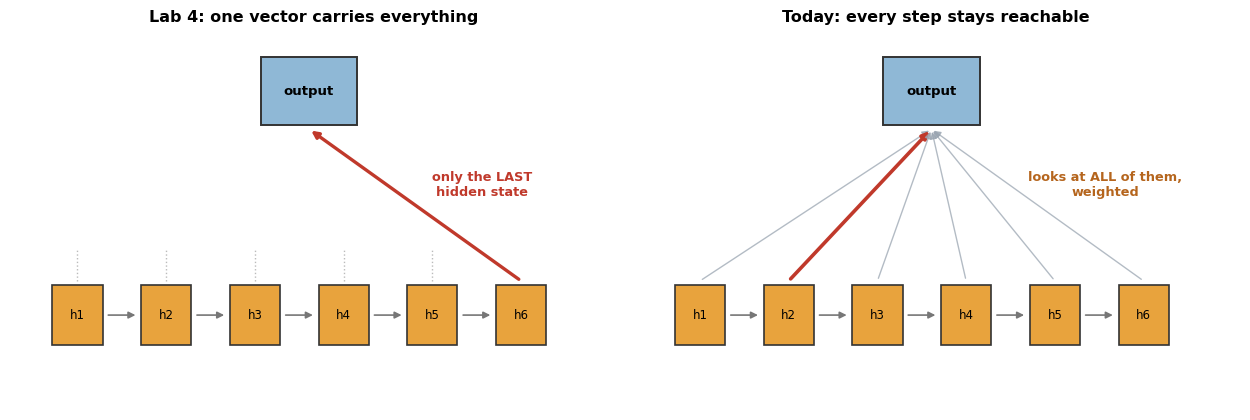

In [3]:
draw_bottleneck_vs_attention(T=6)
plt.show()

On the left, Lab 4. On the right, today. Keep every hidden state, and at each output step decide
**which ones to look at**. Nothing is compressed, so nothing is lost.

The only question left is how a network decides where to look — and the answer is a weighted
average whose weights it computes itself.

---
# Stage 2 · Query, Key, Value

## A lookup table that blurs

Think of a Python dictionary. You supply a key, it matches exactly one stored key, you get back
one value. Attention is that, made **soft and differentiable**:

* the **query** is what you are looking for;
* the **keys** are labels on everything stored;
* the **values** are the contents you actually want back.

Compare the query against every key, turn the comparisons into weights that sum to one, and return
the weighted blend of the values. A dictionary returns one value; attention returns a mixture,
dominated by whichever key matched best.

That difference is the entire point. An exact lookup has no gradient — you cannot nudge it. A
weighted blend is smooth, so backpropagation can flow through it and the network can *learn* where
to look.

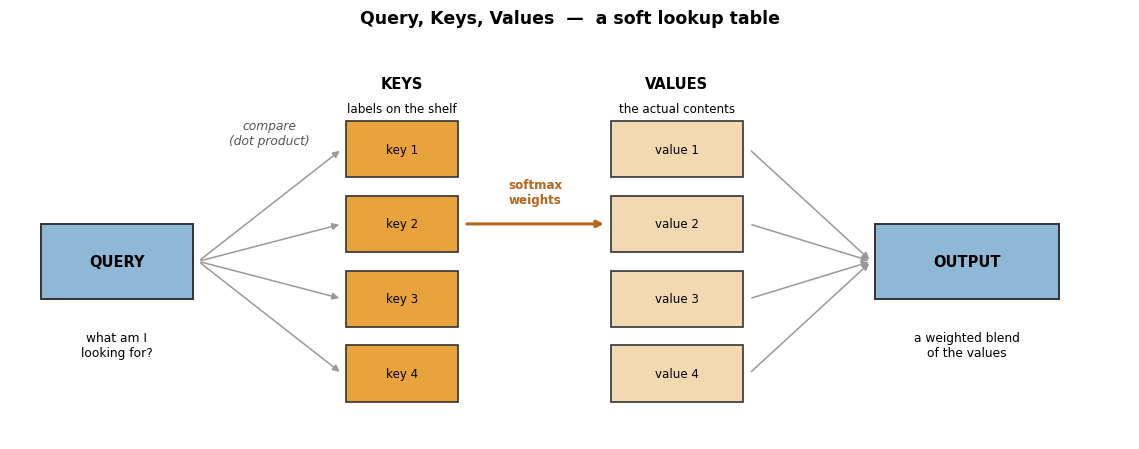

In [4]:
draw_qkv_mechanism()
plt.show()

In symbols, this is the whole mechanism:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_k}}\right)V$$

Read it right to left and it is four steps you already know:

1. $QK^{\top}$ — a dot product between every query and every key. Big when they point the same way.
2. $/\sqrt{d_k}$ — divide by the square root of the key width. Stage 3 shows why.
3. $\text{softmax}$ — turn scores into weights that sum to 1. Lab 2's function, unchanged.
4. $\times V$ — the weighted average of the values.

No new mathematics. A dot product, a divide, a softmax, a matrix multiply.

### Exercise 1 — write it

In [5]:
def softmax(x, axis=-1):
    """Lab 2's softmax, with the max subtracted for stability."""
    e = np.exp(x - x.max(axis=axis, keepdims=True))
    return e / e.sum(axis=axis, keepdims=True)


def attention(Q, K, V, mask=None):
    """Scaled dot-product attention.

    Q : (n_queries, d_k)   K : (n_keys, d_k)   V : (n_keys, d_v)
    Returns (output, weights) where weights is (n_queries, n_keys).
    """
    d_k = K.shape[-1]

    # TODO 1: scores = Q times K-transpose, divided by sqrt(d_k)
    scores = (Q @ K.T) / np.sqrt(d_k)

    if mask is not None:                       # used in the Assessment
        scores = np.where(mask, scores, -1e9)

    # TODO 2: turn the scores into weights with softmax, along the last axis
    weights = softmax(scores, axis=-1)

    # TODO 3: the output is the weights times V
    output = weights @ V

    return output, weights


# --- self-check -------------------------------------------------
Qc = np.array([[1.0, 0.0]])
Kc = np.array([[1.0, 0.0], [0.0, 1.0]])
Vc = np.array([[10.0], [20.0]])
o, w = attention(Qc, Kc, Vc)
assert w.shape == (1, 2), "one weight per key, per query"
assert np.allclose(w.sum(axis=1), 1.0), "each row of weights must sum to 1"
assert o.shape == (1, 1), "output is a blend of the values"
assert o[0, 0] < 15, "the query matches key 1, so the output should lean towards 10"
print("attention() works")
print("weights:", w[0], "  output:", o[0])

attention() works
weights: [0.67 0.33]   output: [13.302]


### Exercise 2 — a lookup table you can check by hand

Four memory slots with one-hot keys, so you can see exactly what should be retrieved. Watch what
changes as the query gets more confident, and what happens when it is torn between two slots.

In [6]:
K = np.eye(4)                                   # four one-hot keys
V = np.array([[10., 0.],
              [20., 1.],
              [30., 2.],
              [40., 3.]])                       # what each slot stores

# TODO 1: a query that asks for slot 2 (index 1): one-hot, shape (1, 4)
q_exact = np.array([[0., 1., 0., 0.]])
out, w = attention(q_exact, K, V)
print(f"exact query      weights {w[0]}  output {out[0]}")

# TODO 2: the same query, multiplied by 5 - a more confident question
q_sharp = 5 * q_exact
out, w = attention(q_sharp, K, V)
print(f"5x sharper       weights {w[0]}  output {out[0]}")

# TODO 3: a query torn between slots 1 and 2: [3, 3, 0, 0]
q_split = np.array([[3., 3., 0., 0.]])
out, w = attention(q_split, K, V)
print(f"torn 1 and 2     weights {w[0]}  output {out[0]}")

print("\nThe last output is roughly the AVERAGE of 10 and 20 - attention blends,")
print("it does not choose. That is exactly what makes it differentiable.")

exact query      weights [0.215 0.355 0.215 0.215]  output [24.302  1.43 ]
5x sharper       weights [0.066 0.802 0.066 0.066]  output [21.317  1.132]
torn 1 and 2     weights [0.409 0.409 0.091 0.091]  output [18.649  0.865]

The last output is roughly the AVERAGE of 10 and 20 - attention blends,
it does not choose. That is exactly what makes it differentiable.


Three things worth pausing on.

The exact query puts the most weight on the right slot, but **not all of it** — the others keep a
share. Attention is soft by construction.

Multiplying the query by 5 makes the distribution much peakier without changing which slot wins.
The *magnitude* of a query controls how decisive the lookup is, and that magnitude is something a
network can learn.

The torn query returns a genuine blend, close to the average of the two values. If you have ever
wondered how a language model produces something that is not in its training data, this is a large
part of the answer.

---
# Stage 3 · Why divide by $\sqrt{d_k}$

## The quietest line in the formula

Of all four steps, the division looks the most arbitrary. It is the one that stops the whole thing
collapsing.

A dot product of two $d_k$-dimensional random vectors is a sum of $d_k$ products. Add more terms
and the sum spreads out — its variance grows with $d_k$. Feed very large scores into a softmax and
one of them wins outright: the weights become one-hot, every other gradient goes to zero, and
learning stops dead.

Dividing by $\sqrt{d_k}$ cancels that growth and keeps the scores in a range where softmax stays
soft.

### Exercise 3 — measure it

In [7]:
rng = np.random.RandomState(0)

print(f"{'d_k':>6}{'raw score range':>26}{'max weight raw':>17}{'max weight scaled':>20}")
for d in [4, 64, 512]:
    q = rng.randn(1, d)
    k = rng.randn(6, d)

    raw = (q @ k.T)[0]
    # TODO: the scaled scores - raw divided by the square root of d
    scaled = raw / np.sqrt(d)

    print(f"{d:6d}   {raw.min():9.2f} to {raw.max():7.2f}"
          f"{softmax(raw).max():17.3f}{softmax(scaled).max():20.3f}")

print("\nAt d_k = 512 the unscaled softmax has collapsed onto one key.")
print("Every other gradient is now zero, and the layer has stopped learning.")

   d_k           raw score range   max weight raw   max weight scaled
     4       -5.06 to    3.49            0.332               0.272
    64      -11.37 to    4.99            0.969               0.320
   512      -24.36 to   11.33            1.000               0.300

At d_k = 512 the unscaled softmax has collapsed onto one key.
Every other gradient is now zero, and the layer has stopped learning.


Look at the last row. Unscaled, one key takes a weight of **1.000** — the softmax has saturated and
the layer is dead. Scaled, the largest weight is about 0.30 and every key still contributes.

Real transformers use $d_k = 64$ per head, where the effect is already severe. This single division
is the difference between a working layer and one that silently refuses to learn.

> **A pattern you have now seen three times.** Lab 2 subtracted the max inside softmax to stop
> overflow. Lab 6 showed initialization scale deciding whether signals vanish or explode through
> ten layers. Here, one divide keeps a softmax in its useful range. Deep learning is full of small
> scaling fixes that look cosmetic and are structural.

---
# Stage 4 · Attention beats the bottleneck

## A fair fight, with no training at all

Here is a test that needs no network. Store `T` key–value pairs. Ask for one of them by its exact
key. Check whether what comes back is the right value.

Attention does this by looking directly at the slot it wants. The Lab 4 approach has to go through
a single summary vector — which we will simulate in the simplest possible way, by averaging all
the values into one. That is the bottleneck, stripped to its essence.

Because nothing is trained, the result is a property of the **architecture**, not of an optimizer
or a seed.

### Exercise 4 — run the sweep

In [8]:
def retrieval_trial(T, d=16, rng=None):
    """Store T random key-value pairs, ask for one by its exact key."""
    K = rng.randn(T, d)
    V = rng.randn(T, d)
    i = rng.randint(T)                          # the slot we want back
    q = K[i:i + 1] * 4.0                        # ask for it, confidently

    # TODO 1: run attention to get the retrieved vector (ignore the weights)
    out_attn, _ = attention(q, K, V)

    # the bottleneck: every value crushed into one summary vector
    summary = V.mean(axis=0, keepdims=True)

    # which stored value is each result closest to?
    pick_attn = int(np.argmin(((V - out_attn) ** 2).sum(axis=1)))
    pick_bott = int(np.argmin(((V - summary) ** 2).sum(axis=1)))
    return pick_attn == i, pick_bott == i


rng = np.random.RandomState(0)
lengths = [2, 4, 8, 16, 32, 64]
acc_attention, acc_bottleneck = [], []

for T in lengths:
    hits_a = hits_b = 0
    trials = 400
    for _ in range(trials):
        ha, hb = retrieval_trial(T, rng=rng)
        hits_a += ha
        hits_b += hb
    acc_attention.append(hits_a / trials)
    acc_bottleneck.append(hits_b / trials)
    print(f"T = {T:3d}   attention {hits_a/trials:.3f}   "
          f"bottleneck {hits_b/trials:.3f}   chance {1/T:.3f}")

# --- self-check ---
assert acc_attention[-1] > 0.85, "attention should barely care about length"
assert acc_bottleneck[-1] < 0.10, "the bottleneck should collapse towards chance"

T =   2   attention 1.000   bottleneck 0.430   chance 0.500
T =   4   attention 0.993   bottleneck 0.225   chance 0.250
T =   8   attention 0.990   bottleneck 0.135   chance 0.125
T =  16   attention 0.990   bottleneck 0.050   chance 0.062
T =  32   attention 0.980   bottleneck 0.035   chance 0.031
T =  64   attention 0.958   bottleneck 0.015   chance 0.016


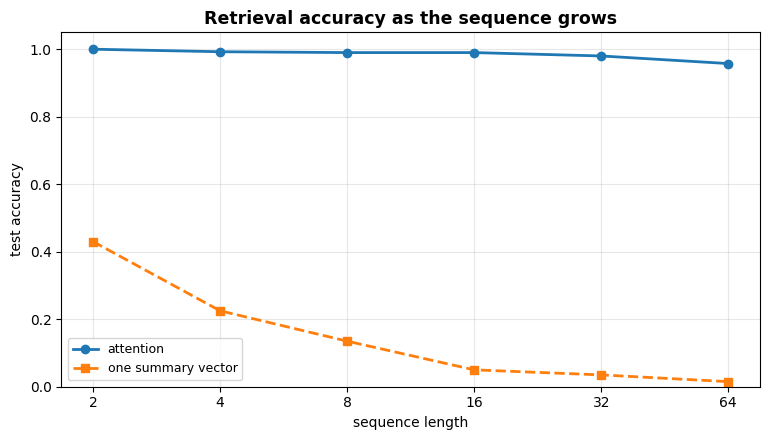

In [9]:
draw_length_sweep(lengths,
                  {"attention": acc_attention, "one summary vector": acc_bottleneck},
                  title="Retrieval accuracy as the sequence grows")
plt.show()

Attention is still right about 96% of the time at length 64. The bottleneck tracks the chance line
almost exactly — averaging everything into one vector destroys the information completely, and it
does so immediately, not gradually.

Put that beside Lab 4's table. Your LSTM held on much better than this crude baseline, because its
gates learned *what* to keep. But it was still rationing one vector, and at length 80 it was down
to 0.79. Attention never rations, so length costs it almost nothing.

**This is why transformers replaced recurrent networks.** Not because attention is cleverer, but
because it removed a constraint rather than managing one.

---
---
# Stage 5 · Self-attention

## When the sequence looks at itself

So far queries came from one place and keys and values from another — a decoder querying an
encoder, which is how attention was first used, for translation.

**Self-attention** does something simpler and stranger. The queries, keys and values all come from
the *same* sequence:

```python
output, weights = attention(X, X, X)
```

Every position asks every other position how relevant it is, and rebuilds itself as a blend of the
whole sequence. In "the cat sat on the mat", `sat` can draw on `cat` directly, with no steps in
between.

This is the layer the entire transformer is built from — and through it, every large language
model you have used.

### Exercise 5 — self-attention on a sentence

sequence: (6, 8)  (6 words, 8 numbers each)

every row sums to 1: True


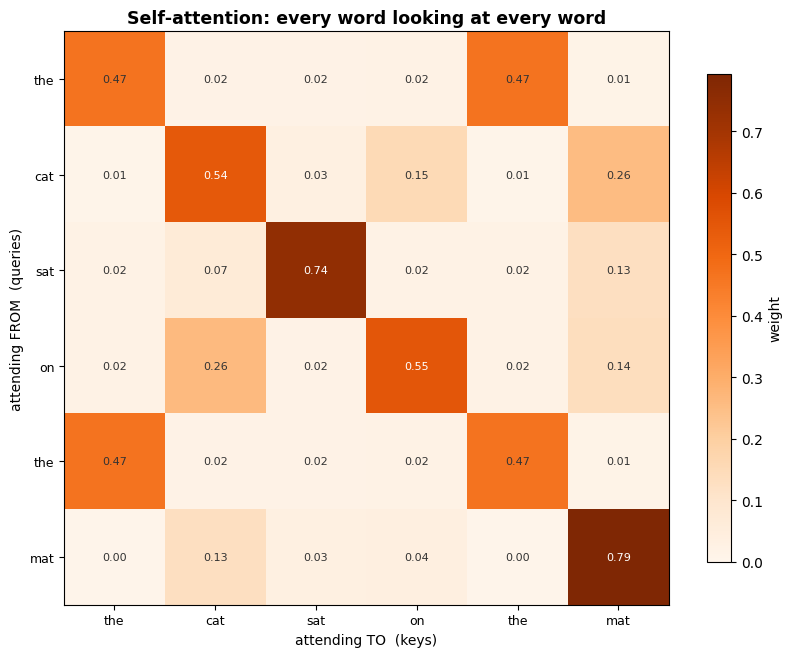

In [10]:
words = ["the", "cat", "sat", "on", "the", "mat"]

rng2 = np.random.RandomState(3)
d = 8
vocab = {w: rng2.randn(d) for w in set(words)}     # random stand-in embeddings
X = np.array([vocab[w] for w in words])
print("sequence:", X.shape, " (6 words, 8 numbers each)")

# TODO: self-attention - the same X used as query, key AND value
out, W = attention(X, X, X)

print("\nevery row sums to 1:", np.allclose(W.sum(axis=1), 1.0))

draw_attention_heatmap(W, row_labels=words, col_labels=words,
                       title="Self-attention: every word looking at every word")
plt.show()

# --- self-check ---
assert W.shape == (6, 6), "6 words attending to 6 words"
assert out.shape == X.shape, "each position is rebuilt, same shape"

Two things in that heatmap, and the second is a genuine flaw.

**The diagonal is bright.** Every word attends mostly to itself, because a vector's dot product
with itself is the largest score available. Sensible, and no one had to program it.

**Rows 1 and 5 are identical.** Both are the word "the", and attention has treated them as exactly
the same thing — because *it has no idea they are in different places*. The formula contains no
notion of order whatsoever. Shuffle the sentence and the weights shuffle with it, unchanged.

In [11]:
print("row for 'the' at position 0 :", W[0])
print("row for 'the' at position 4 :", W[4])
print("identical?", np.allclose(W[0], W[4]))

row for 'the' at position 0 : [0.466 0.016 0.018 0.019 0.466 0.015]
row for 'the' at position 4 : [0.466 0.016 0.018 0.019 0.466 0.015]
identical? True


That is a serious problem for language, where "the cat sat on the mat" and "the mat sat on the cat"
are different sentences. The fix is **positional encoding**: add a position-dependent vector to
each embedding before attention, so the two "the"s arrive carrying different information. It is a
patch over a real hole, and now you know exactly which hole.

### Idea 6 — Multi-head attention, in one paragraph

One attention layer computes one set of weights, so it can emphasise one kind of relationship.
Real models run several in parallel — **heads** — each with its own learned projections of Q, K and
V, then concatenate the results. One head might track grammatical subjects, another nearby words,
another long-range references. Same formula, run eight or sixteen times on different projections
of the same input.

Everything you have built today is one head. That is the whole of the extension.

---
# Assessment

## Q1 — Masking, and how GPT works

Self-attention lets every position see every other — including positions **after** it. For
translation that is fine; the whole input sentence is available.

For *generating* text it is fatal. A model predicting word 5 must not be allowed to look at word 6,
or it will learn to cheat and then fail completely at generation time, when the future does not yet
exist.

The fix is a **causal mask**: before the softmax, set every score that looks forward to $-\infty$.
After softmax those become exactly zero. Your `attention` function already supports this through
its `mask` argument.

This one change is the only structural difference between the encoder of a translation model and
the decoder that powers GPT.

the mask (True = allowed):
[[1 0 0 0 0]
 [1 1 0 0 0]
 [1 1 1 0 0]
 [1 1 1 1 0]
 [1 1 1 1 1]]

causal attention weights:
[[1.    0.    0.    0.    0.   ]
 [0.423 0.577 0.    0.    0.   ]
 [0.273 0.247 0.48  0.    0.   ]
 [0.089 0.113 0.039 0.758 0.   ]
 [0.236 0.177 0.153 0.076 0.358]]


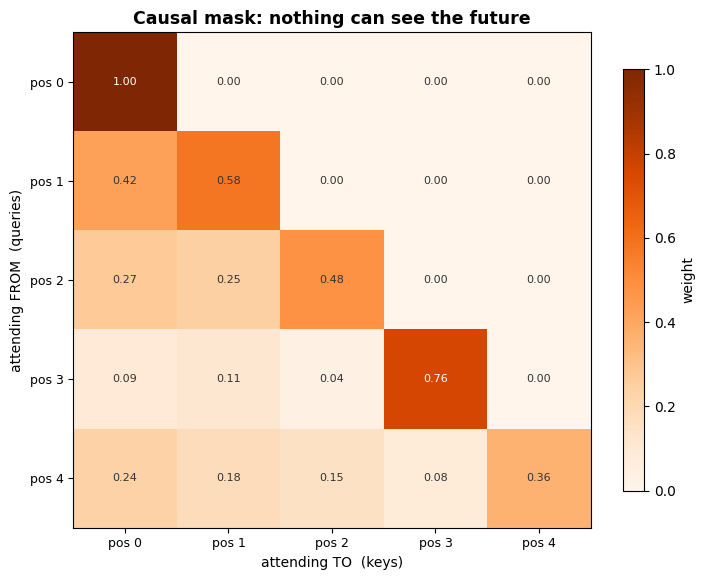

In [12]:
T = 5

# TODO 1: a boolean (T, T) mask, True where attending is ALLOWED.
#         Position i may see positions 0..i, so this is a lower triangle.
#         Hint: np.tril with np.ones((T, T), dtype=bool)
causal = np.tril(np.ones((T, T), dtype=bool))

print("the mask (True = allowed):")
print(causal.astype(int))

rng3 = np.random.RandomState(1)
Xc = rng3.randn(T, 6)

# TODO 2: self-attention over Xc, passing the mask
out_c, W_c = attention(Xc, Xc, Xc, mask=causal)

print("\ncausal attention weights:")
print(W_c)

draw_attention_heatmap(W_c,
                       row_labels=[f"pos {i}" for i in range(T)],
                       col_labels=[f"pos {i}" for i in range(T)],
                       title="Causal mask: nothing can see the future")
plt.show()

# --- self-check ---
assert np.allclose(np.triu(W_c, 1), 0), "nothing above the diagonal may have weight"
assert np.allclose(W_c.sum(axis=1), 1.0), "rows must still sum to 1"
assert np.allclose(W_c[0], [1, 0, 0, 0, 0]), "position 0 can only see itself"

Record the first row of `W_c` and explain, in one sentence, why it has to look like that.

**Answer:** The first row is `[1, 0, 0, 0, 0]` because causal masking allows position 0 to attend only to itself, not to any future position.

## Q2 — What the mask costs

Compare the same sequence with and without the mask.

In [13]:
_, W_free = attention(Xc, Xc, Xc)

print(f"{'position':>10}{'keys visible':>15}{'self, unmasked':>18}{'self, masked':>16}")
for i in range(T):
    # TODO 1: how many keys can position i actually see under the mask?
    #          (count the True values in row i of `causal`)
    visible = int(np.sum(causal[i]))
    # TODO 2: the weight position i puts on ITSELF, unmasked then masked
    self_free = W_free[i, i]
    self_mask = W_c[i, i]
    print(f"{i:10d}{visible:15d}{self_free:18.3f}{self_mask:16.3f}")

  position   keys visible    self, unmasked    self, masked
         0              1             0.585           1.000
         1              2             0.556           0.577
         2              3             0.412           0.480
         3              4             0.695           0.758
         4              5             0.358           0.358


| position | keys visible | weight on itself, unmasked | weight on itself, masked |
|---|---|---|---|
| 0 | | | |
| 1 | | | |
| 2 | | | |
| 3 | | | |
| 4 | | | |


---
## Submission

1. Create a new repository on GitHub for this course and name it `arti402`.
2. Rename this file to `arti402_Lab10_<YourID>.ipynb` and upload the completed notebook, with all
   outputs visible, to your repository.